In [4]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from statsforecast.models import Naive, SeasonalNaive

from src.forecasting.backtest import evaluate, run_statsforecast, summarise, train_part
from src.forecasting.data import to_nixtla

df = pd.read_parquet(ROOT / "data" / "processed" / "sales_long.parquet")
classes = pd.read_parquet(ROOT / "data" / "processed" / "item_classes.parquet")
train = train_part(to_nixtla(df))

ids = train["unique_id"].unique()[:40]  # só 40 produtos, para testar
res = run_statsforecast(
    [Naive(), SeasonalNaive(season_length=7)], train[train["unique_id"].isin(ids)]
)
summarise(evaluate(res, train, classes)).round(3)

,model,demand_class,mae,rmsse,bias,n_items
5,SeasonalNaive,all,1.941,1.012,-0.142,40
0,Naive,all,2.006,1.043,0.060,40
6,SeasonalNaive,erratic,4.197,0.871,-0.025,5
1,Naive,erratic,4.483,0.877,0.364,5
7,SeasonalNaive,intermittent,1.026,0.982,-0.140,24
2,Naive,intermittent,1.052,1.010,-0.026,24
8,SeasonalNaive,lumpy,2.708,0.989,-0.459,5
3,Naive,lumpy,2.771,1.092,-0.421,5
9,SeasonalNaive,smooth,3.081,1.271,-0.194,6
4,Naive,smooth,3.119,1.271,-0.055,6


Text(0.5, 0, 'Share of gain')

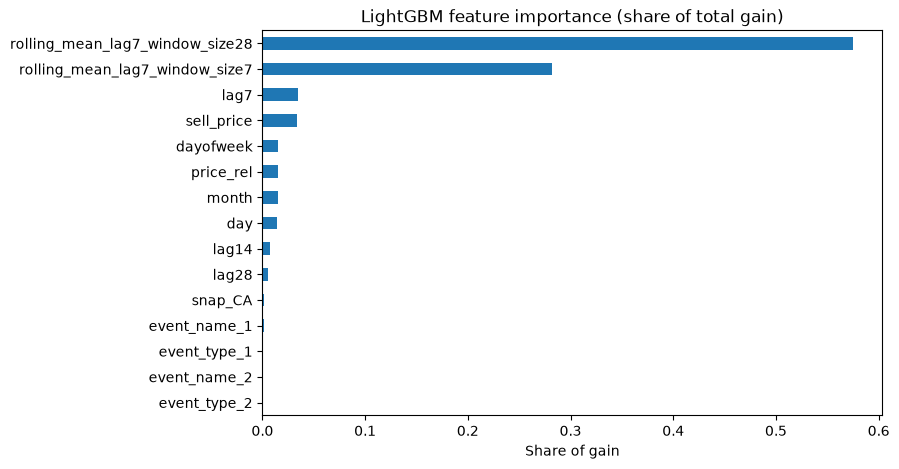

In [5]:
from src.forecasting.ml import add_ml_features, make_mlforecast

fcst = make_mlforecast()
fcst.fit(add_ml_features(train), static_features=[])

model = fcst.models_["LightGBM"]
importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=model.booster_.feature_name(),
)
importance = (importance / importance.sum()).sort_values()

ax = importance.plot.barh(figsize=(8, 5), color="tab:blue")
ax.set_title("LightGBM feature importance (share of total gain)")
ax.set_xlabel("Share of gain")

O modelo depende sobretudo do nível recente de vendas (médias de 7 e 28 dias). O preço e o dia da semana ajudam pouco, e os eventos quase nada.

In [6]:
from src.forecasting.backtest import evaluate, run_mlforecast, summarise

trials = {
    "base (63 leaves, lr 0.05)": {},
    "31 leaves": {"num_leaves": 31},
    "127 leaves, 100 min samples": {"num_leaves": 127, "min_child_samples": 100},
    "lr 0.03, 800 trees": {"learning_rate": 0.03, "n_estimators": 800},
}

rows = []
for name, params in trials.items():
    res = run_mlforecast(make_mlforecast(**params), train)
    s = summarise(evaluate(res, train, classes)).set_index("demand_class")
    rows.append({"trial": name, **s["rmsse"].round(3).to_dict()})
    print(name, "done")

pd.DataFrame(rows).set_index("trial")

base (63 leaves, lr 0.05) done
31 leaves done
127 leaves, 100 min samples done
lr 0.03, 800 trees done


,all,erratic,intermittent,lumpy,smooth
trial,,,,,
"base (63 leaves, lr 0.05)",0.745,0.680,0.760,0.698,0.806
31 leaves,0.745,0.679,0.760,0.696,0.806
"127 leaves, 100 min samples",0.745,0.680,0.759,0.699,0.805
"lr 0.03, 800 trees",0.745,0.680,0.759,0.699,0.806


All four settings give RMSSE 0.745 overall, with differences of at most 0.002 per class.
The model is not sensitive to these parameters, so the base setting is kept.

In [7]:
from src.forecasting.selection import build_hybrid

POINT_MODEL = {
    "smooth": "LightGBM",
    "erratic": "LightGBM",
    "intermittent": "AutoETS",
    "lumpy": "AutoETS",
}

calibrated = pd.read_parquet(ROOT / "results" / "calibrated_backtest.parquet")
hybrid = build_hybrid(calibrated, classes, POINT_MODEL, interval_model="AutoETS")
candidates = pd.concat([calibrated[calibrated["model"].isin(["AutoETS", "LightGBM"])], hybrid])

choice = summarise(evaluate(candidates, train, classes))
choice[
    [
        "model",
        "demand_class",
        "rmsse",
        "bias",
        "coverage_q90",
        "coverage_q95",
        "pinball_q90",
        "pinball_q95",
    ]
].round(3)

,model,demand_class,rmsse,bias,coverage_q90,coverage_q95,pinball_q90,pinball_q95
5,Hybrid,all,0.734,-0.081,0.903,0.952,0.493,0.323
0,AutoETS,all,0.743,-0.063,0.902,0.951,0.503,0.329
10,LightGBM,all,0.745,-0.033,0.894,0.945,0.611,0.470
6,Hybrid,erratic,0.680,-0.076,0.913,0.951,0.895,0.591
11,LightGBM,erratic,0.680,-0.076,0.880,0.933,1.195,0.948
1,AutoETS,erratic,0.712,-0.084,0.906,0.947,0.926,0.611
2,AutoETS,intermittent,0.742,-0.061,0.903,0.954,0.256,0.163
7,Hybrid,intermittent,0.742,-0.061,0.903,0.954,0.256,0.163
12,LightGBM,intermittent,0.760,0.100,0.901,0.951,0.281,0.200
3,AutoETS,lumpy,0.683,-0.077,0.907,0.953,0.405,0.278


Hybrid chosen: LightGBM point for smooth and erratic items, AutoETS for intermittent and lumpy, with AutoETS intervals. Best RMSSE and pinball loss on validation

In [8]:
import matplotlib.pyplot as plt

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

test = pd.read_csv(ROOT / "results" / "summary_test.csv")
MODELS = ["SeasonalNaive", "WindowAverage", "AutoETS", "LightGBM", "Hybrid"]
COLORS = {
    "SeasonalNaive": "silver",
    "WindowAverage": "dimgray",
    "AutoETS": "tab:orange",
    "LightGBM": "tab:green",
    "Hybrid": "tab:blue",
}
CLASSES = ["all", "smooth", "erratic", "intermittent", "lumpy"]

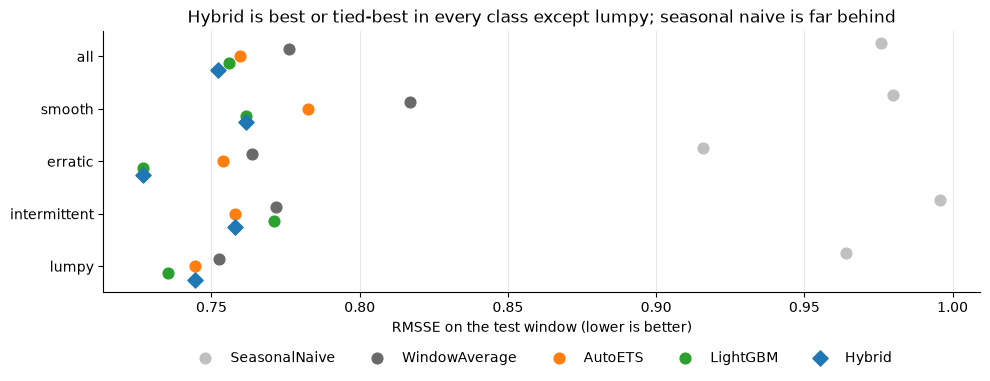

In [9]:
rmsse = test.pivot(index="demand_class", columns="model", values="rmsse").loc[CLASSES, MODELS]

fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(MODELS):
    offset = (i - 2) * 0.13  # spread the models vertically so ties stay visible
    ax.scatter(
        rmsse[m],
        [k + offset for k in range(len(CLASSES))],
        s=60,
        color=COLORS[m],
        label=m,
        zorder=3,
        marker="D" if m == "Hybrid" else "o",
    )
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("RMSSE on the test window (lower is better)")
ax.set_title(
    "Hybrid is best or tied-best in every class except lumpy; seasonal naive is far behind"
)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

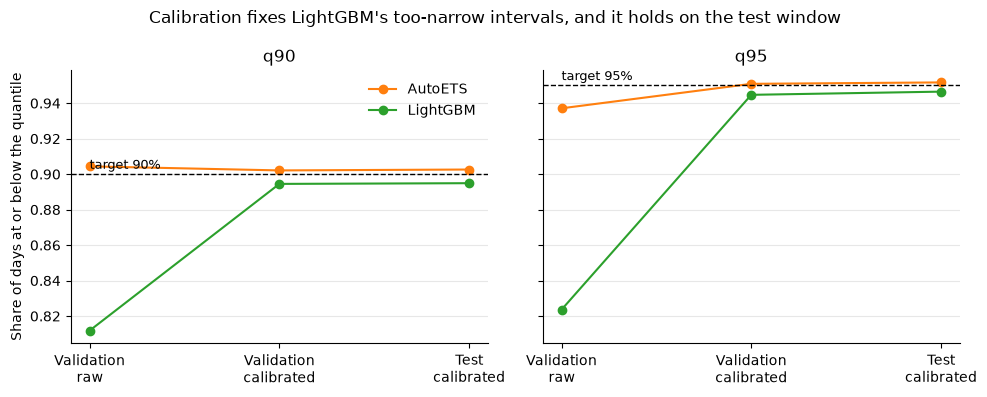

In [10]:
raw = pd.read_csv(ROOT / "results" / "summary.csv")
cal = pd.read_csv(ROOT / "results" / "summary_calibrated.csv")

rows = []
stages = [("Validation\nraw", raw), ("Validation\ncalibrated", cal), ("Test\ncalibrated", test)]
for stage, table in stages:
    t = table[(table["demand_class"] == "all") & table["model"].isin(["AutoETS", "LightGBM"])]
    for _, r in t.iterrows():
        rows.append(
            {
                "stage": stage,
                "model": r["model"],
                "q90": r["coverage_q90"],
                "q95": r["coverage_q95"],
            }
        )
cov = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, q, target in zip(axes, ["q90", "q95"], [0.90, 0.95]):
    for m in ["AutoETS", "LightGBM"]:
        g = cov[cov["model"] == m]
        ax.plot(g["stage"], g[q], marker="o", color=COLORS[m], label=m)
    ax.axhline(target, color="black", linestyle="--", linewidth=1)
    ax.text(0, target + 0.003, f"target {target:.0%}", fontsize=9)
    ax.set_title(q)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Share of days at or below the quantile")
axes[0].legend(frameon=False)
fig.suptitle("Calibration fixes LightGBM's too-narrow intervals, and it holds on the test window")
plt.tight_layout()
plt.show()

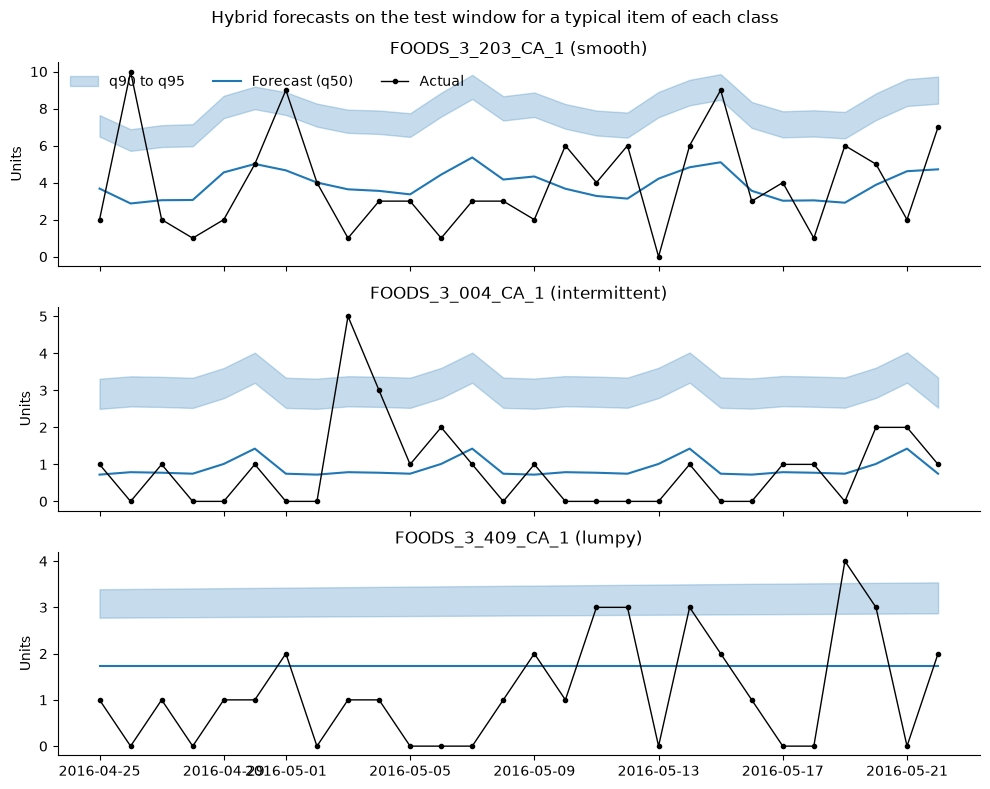

In [11]:
forecasts = pd.read_parquet(ROOT / "results" / "test_forecasts.parquet")
cls = classes.assign(
    unique_id=classes["item_id"].astype(str) + "_" + classes["store_id"].astype(str)
)[["unique_id", "demand_class"]]
hybrid_test = forecasts[forecasts["model"] == "Hybrid"].merge(cls, on="unique_id")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, k in zip(axes, ["smooth", "intermittent", "lumpy"]):
    totals = hybrid_test[hybrid_test["demand_class"] == k].groupby("unique_id")["y"].sum()
    uid = (totals - totals.median()).abs().idxmin()  # a typical item of this class
    g = hybrid_test[hybrid_test["unique_id"] == uid]
    ax.fill_between(g["ds"], g["q90"], g["q95"], color="tab:blue", alpha=0.25, label="q90 to q95")
    ax.plot(g["ds"], g["mean"], color="tab:blue", label="Forecast (q50)")
    ax.plot(g["ds"], g["y"], color="black", marker="o", markersize=3, linewidth=1, label="Actual")
    ax.set_title(f"{uid} ({k})")
    ax.set_ylabel("Units")
axes[0].legend(ncol=3, frameon=False, loc="upper left")
fig.suptitle("Hybrid forecasts on the test window for a typical item of each class")
plt.tight_layout()
plt.show()

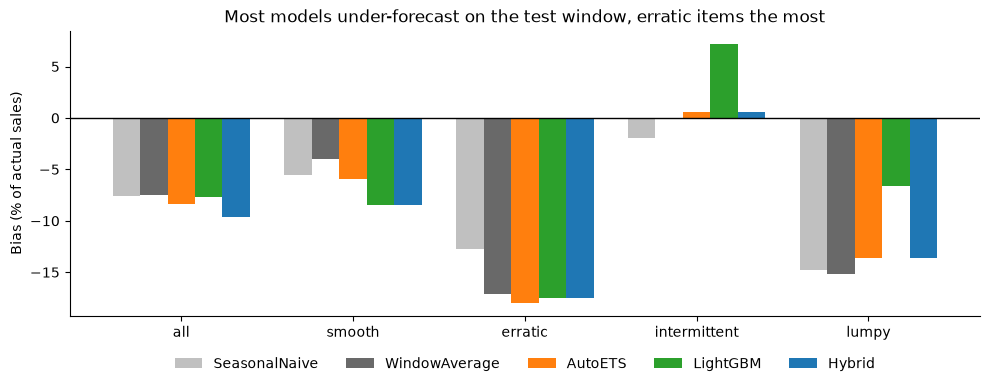

In [12]:
bias = test.pivot(index="demand_class", columns="model", values="bias").loc[CLASSES, MODELS] * 100

ax = bias.plot.bar(figsize=(10, 4), width=0.8, rot=0, color=[COLORS[m] for m in MODELS])
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Most models under-forecast on the test window, erratic items the most")
ax.set_ylabel("Bias (% of actual sales)")
ax.set_xlabel("")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

## Findings

1. **Hybrid wins on the test window:** RMSSE 0.752, 23% below seasonal naive (0.976) and 3% below the
   28-day moving average (0.776). It uses LightGBM for smooth and erratic items and AutoETS for
   intermittent and lumpy items.
2. **Calibrated quantiles hold out of sample:** q90 and q95 cover 90.1% and 95.2% of test days, with
   factors fitted only on validation. Raw conformal intervals covered only about 82% at q95.
3. **AutoETS gives the sharpest quantiles in every class**, even where LightGBM has the better point
   forecast, so the Hybrid takes its intervals from AutoETS.
4. **Honest negative:** on lumpy items LightGBM beat AutoETS on the test window (0.735 vs 0.745), the
   opposite of validation. The validation choice is kept.
5. **All models under-forecast** (Hybrid bias −9.6%, erratic items about −17%). Phase 2 should set
   stock from q90/q95, not from the point forecast.